# Deep Learning Week 5


## Assignment 51: Linear Regression

**Question:** Implement a linear regression model using scikit-learn to predict students' exam scores from their study hours.


Slope: 7.2844827586206895
Intercept: 5.810344827586206

Actual scores: [70 20]
Predicted scores: [71.37 20.38]

Mean Absolute Error: 0.875
Mean Squared Error: 1.0113332342449455
R-squared Score: 0.9983818668252081

Predicted score for 7.5 study hours: 60.44


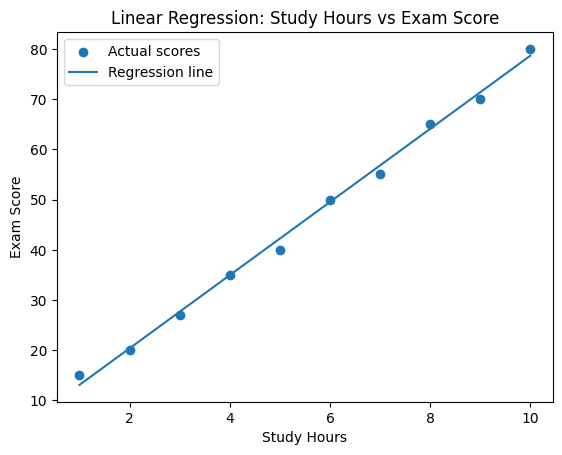

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Dataset: study hours and exam scores
X = np.array([
    [1], [2], [3], [4], [5],
    [6], [7], [8], [9], [10]
])

y = np.array([15, 20, 27, 35, 40, 50, 55, 65, 70, 80])

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

print("\nActual scores:", y_test)
print("Predicted scores:", np.round(y_pred, 2))

# Evaluate the model
print("\nMean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R-squared Score:", r2_score(y_test, y_pred))

# Predict the score for a student studying 7.5 hours
hours = np.array([[7.5]])
predicted_score = model.predict(hours)

print("\nPredicted score for 7.5 study hours:",
      round(predicted_score[0], 2))

# Visualize the regression line
plt.scatter(X, y, label="Actual scores")
plt.plot(X, model.predict(X), label="Regression line")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Linear Regression: Study Hours vs Exam Score")
plt.legend()
plt.show()

## Assignment 52: Logistic Regression

**Question:** Implement a logistic regression model using scikit-learn to classify students as pass or fail based on their study hours and attendance.

In [2]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Dataset: [study hours, attendance percentage]
X = np.array([
    [1, 40], [2, 45], [1, 50], [2, 55],
    [3, 50], [3, 60], [4, 55], [4, 65],
    [5, 60], [5, 70], [6, 65], [6, 75],
    [7, 70], [7, 80], [8, 75], [8, 85],
    [9, 80], [9, 90], [10, 85], [10, 95],
    [2, 35], [3, 40], [4, 45], [5, 50],
    [6, 55], [7, 60], [8, 65], [9, 70],
    [1, 30], [10, 98]
])

# 0 = Fail, 1 = Pass
y = np.array([
    0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
    0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    0, 0, 0, 0, 1, 1, 1, 1, 0, 1
])

# Split the dataset while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scale features and train logistic regression
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

# Predict test labels
y_pred = model.predict(X_test)

print("Actual labels:", y_test)
print("Predicted labels:", y_pred)

# Evaluate the classifier
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))

# Predict for a new student
# Study hours = 6, attendance = 75%
new_student = np.array([[6, 75]])

prediction = model.predict(new_student)[0]
probabilities = model.predict_proba(new_student)[0]

print("\nNew student prediction:",
      "Pass" if prediction == 1 else "Fail")

print("Probability of Fail:", round(probabilities[0], 3))
print("Probability of Pass:", round(probabilities[1], 3))

Actual labels: [0 1 1 1 0 1 0 0]
Predicted labels: [0 1 1 1 0 1 0 0]

Accuracy: 1.0

Confusion Matrix:
[[4 0]
 [0 4]]

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         4
        Pass       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8


New student prediction: Pass
Probability of Fail: 0.253
Probability of Pass: 0.747
